# Lab: Logistic Regression
Decision boundaries: from 4 students (using NumPy) to a tumor classifier (using scikit-learn).

- Sigmoid and log loss
- Gradient
- Decision threshold
- C * L2
- L1

---

## Logistic Regression: Implementation Overview

1\. Linear combination: Combines the input features (`x`) with their corresponding weights (`w`) and adds a bias (`b`) to produce a score (`z`).

`z = w · x + b`

2\. Sigmoid function: Converts the score (`z`) into a probability between 0 and 1, representing how likely an observation belongs to class 1.

`σ(z) = 1 / (1 + e^(-z))`

3\. Decision threshold: Converts the predicted probability into a class label. By default:

- If `p ≥ 0.5` → class 1.
- If `p < 0.5` → class 0.

4\. Log Loss and Gradient Descent: Log Loss measures how far the predicted probabilities are from the actual labels. Gradient Descent adjusts the model's weights and bias to minimize this loss, gradually moving toward the minimum of the cost function.

## Implementation Plan

| Part       | Topic            | Main objective                                                                                                                    |
| ---------- | ---------------- | --------------------------------------------------------------------------------------------------------------------------------- |
| 1          | Four students    | Implement Logistic Regression manually with NumPy, then with scikit-learn.                                                        |
| 2          | One feature      | Train a model using one feature from the Breast Cancer dataset and explore the 1D decision boundary and classification threshold. |
| 3          | Two features     | Train using two features, visualize the 2D linear decision boundary, and understand why feature scaling is important.             |
| 4          | All 30 features  | Train using all available features and explore regularization with `C`, L1, and L2.                                               |
| Conclusion | Final evaluation | Test the model using all 30 features and evaluate its classification performance.                                                 |

Key concepts:

- Feature: An input variable used by the model to make predictions.
- Weight (`w`): Determines how strongly each feature influences the prediction.
- Bias (`b`): Shifts the model's decision boundary.
- Decision boundary: The boundary separating the predicted classes.
- Regularization: Helps prevent overfitting by penalizing excessively large weights.
- C parameter: Controls regularization strength in scikit-learn. Smaller `C` means stronger regularization; larger `C` means weaker regularization.
- L1 regularization: Can drive some weights to exactly zero, effectively performing feature selection.
- L2 regularization: Penalizes large weights, encouraging smaller and more evenly distributed coefficients.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import sklearn
print("scikit-learn", sklearn.__version__)

scikit-learn 1.8.0


---
## Part 1 — The Four Students (Manual Implementation)

We use a small dataset with one feature: hours studied.

The target label indicates whether the student passed or failed:

- `1` = Passed.
- `0` = Failed.

| Student | Study hours (`x`) | Passed (`y`) |
| ------- | ----------------- | ------------ |
| A       | 1                 | 0            |
| B       | 2                 | 0            |
| C       | 4                 | 1            |
| D       | 5                 | 1            |

Objective: Train a Logistic Regression model to predict whether a student will pass based on the number of hours studied.

In [2]:
hours = np.array([1, 2, 4, 5], dtype=float)
passed = np.array([0, 0, 1, 1], dtype=float)
alpha = 0.5   # learning rate

---
### 1.1 The Two Class Functions

\- `sigmoid(z)`: The S-shaped function that converts any real-valued input into a probability between 0 and 1.

\- `log_loss(y, p)`: Measures how wrong the model's predicted probability is. It acts as the model's cost function, heavily penalizing predictions that are confidently incorrect.

- If `y = 1` (actual class is positive), the cost is `-ln(p)` → penalizes low predicted probabilities.
- If `y = 0` (actual class is negative), the cost is `-ln(1 - p)` → penalizes high predicted probabilities.

Key idea: The more confidently the model makes an incorrect prediction, the higher the Log Loss. A perfect prediction has a loss close to zero.

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, p):
    eps = 1e-12  # to avoid calculating ln(0)
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print("sigmoid(0)  =", sigmoid(0))      # 0.5 -> the model 'doesn't know'
print("sigmoid(2)  =", round(sigmoid(2), 4))   # 0.8808, as in slide 04
print("sigmoid(-5) =", sigmoid(-5))     # close to 0

# Penalty for an example with y = 1
for p in [0.85, 0.5, 0.05]:
    print(f"y=1, p={p:<4} -> cost = {-np.log(p):.2f}")

sigmoid(0)  = 0.5
sigmoid(2)  = 0.8808
sigmoid(-5) = 0.0066928509242848554
y=1, p=0.85 -> cost = 0.16
y=1, p=0.5  -> cost = 0.69
y=1, p=0.05 -> cost = 3.00


---
### 1.2 The First Iterations, Step by Step

Each iteration follows the same four-step cycle:

1. Predict: Calculate the linear combination (`z`) and pass it through the sigmoid function to obtain predicted probabilities (`p`).

   `z = w · x + b`

   `p = sigmoid(z)`
2. Calculate the loss: Use Log Loss to measure how far the predictions are from the actual labels. This represents the model's current error.
3. Calculate the gradients: Measure how the loss changes with respect to each parameter (weight and bias).
   - Weight gradient: `∂L/∂w = mean((p - y) · x)`
   - Bias gradient: `∂L/∂b = mean(p - y)`
4. Update the parameters: Use Gradient Descent to adjust the weight and bias in the direction that reduces the loss.
   - `w = w - α · ∂L/∂w`
   - `b = b - α · ∂L/∂b`
   Here, `α` (alpha) is the learning rate, which controls the size of each update step.

Key concepts:

- Iteration: One complete cycle of prediction, loss calculation, gradient calculation, and parameter updates.
- Gradient: Indicates the direction and rate at which the loss changes as a parameter changes.
- Learning rate (`α`): Controls how large each parameter update is.
- Gradient Descent: Repeatedly adjusts the model's parameters to minimize the loss.

Important: The gradients are calculated using the current predictions before updating `w` and `b`. Each new iteration uses the updated values.

In [ ]:
# Initial parameter values
w, b = 0.0, 0.0  

for iteration in range(3):
    z = w * hours + b
    p = sigmoid(z)
    loss = log_loss(passed, p)

    error = p - passed
    grad_w = np.mean(error * hours)
    grad_b = np.mean(error)

    print(f"--- Iteration {iteration}: w = {w:.3f}, b = {b:.3f}")
    print("p       =", p.round(4))
    print(f"loss = {loss:.3f}  grad_w = {grad_w:+.3f}  grad_b = {grad_b:+.3f}")

    # Update parameters using Gradient Descent
    w = w - alpha * grad_w
    b = b - alpha * grad_b

--- Iteration 0: w = 0.000, b = 0.000
p       = [0.5 0.5 0.5 0.5]
loss = 0.693  grad_w = -0.750  grad_b = +0.000
--- Iteration 1: w = 0.375, b = 0.000
p       = [0.5927 0.6792 0.8176 0.867 ]
loss = 0.595  grad_w = +0.139  grad_b = +0.239
--- Iteration 2: w = 0.305, b = -0.120
p       = [0.5463 0.6204 0.7507 0.8034]
loss = 0.566  grad_w = -0.048  grad_b = +0.180


---
### Understanding the First Iterations

- Iteration 0: All students receive a predicted probability of `0.5`. The Log Loss is `0.693`, and `grad_w = -0.75`. Therefore, the weight increases:

  `w = 0 - 0.5 × (-0.75) = 0.375`
- Iteration 1: The Log Loss decreases to `0.595`, meaning the model is improving. However, students A and B still receive probabilities above 50% of passing. The bias gradient is positive, so the model decreases the bias to correct these predictions.
- Iteration 2: The Log Loss decreases further to `0.566`, showing continued improvement.

### 1.3 Train for 3,000 Iterations

Instead of manually repeating the training steps, we can place them inside a function and run Gradient Descent 3,000 times.

Key concepts:

- Training: Repeatedly updating the model's parameters to minimize Log Loss.
- Loss history: Stores the loss value at each iteration so we can track the model's improvement.
- Decision boundary: The point where the predicted probability equals `0.5`. In this one-feature example, it is calculated as `x = -b/w`.
- Logarithmic scale: Makes it easier to visualize how the loss changes across iterations, especially during early training.

Expected behavior: As training progresses, Log Loss should decrease and eventually stabilize near its minimum. The decision boundary should approach the point separating students who passed from those who failed.

w = 4.42, b = -12.95
Decision boundary (where p = 0.5): x = 2.93 hours


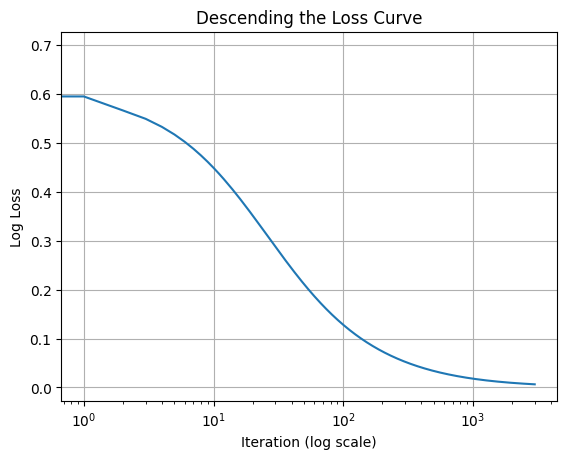

In [5]:
def train(x, y, learning_rate=0.5, iterations=3000):
    w, b = 0.0, 0.0
    history = []

    for i in range(iterations):
        p = sigmoid(w * x + b)
        history.append(log_loss(y, p))

        w -= learning_rate * np.mean((p - y) * x)
        b -= learning_rate * np.mean(p - y)

    return w, b, history


w, b, history = train(hours, passed)

print(f"w = {w:.2f}, b = {b:.2f}")
print(f"Decision boundary (where p = 0.5): x = {-b / w:.2f} hours")

plt.plot(history)
plt.xscale("log")
plt.xlabel("Iteration (log scale)")
plt.ylabel("Log Loss")
plt.title("Descending the Loss Curve")
plt.grid(True)
plt.show()

---
The model converges to approximately the same values: `w ≈ 4.42`, `b ≈ -12.95`, with a decision boundary at approximately `2.93 hours`.

### Why `x = -b/w`?

The predicted probability is exactly `0.5` when the linear combination `z` equals zero.

Starting with:

`w · x + b = 0`

Solving for `x`:

`x = -b / w`

This point is called the decision boundary because it separates the two predicted classes.

### Visualizing the Decision Boundary

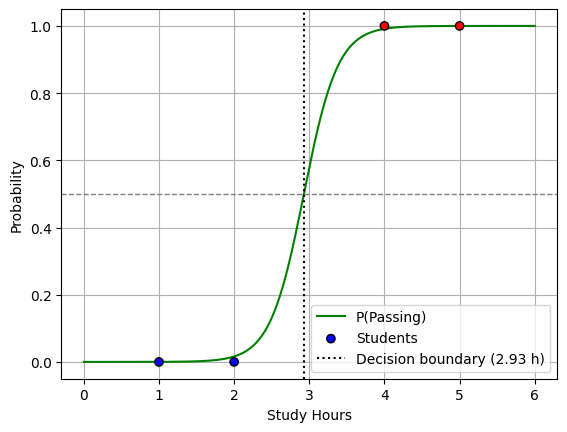

In [6]:
x_plot = np.linspace(0, 6, 300)

plt.plot(x_plot, sigmoid(w * x_plot + b), "g-", label="P(Passing)")
plt.scatter(
    hours, passed,
    c=passed, cmap="bwr",
    edgecolors="k", zorder=3,
    label="Students"
)

plt.axvline(
    -b / w, color="k", linestyle=":",
    label=f"Decision boundary ({-b / w:.2f} h)"
)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)

plt.xlabel("Study Hours")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

---
### 1.4 Implementing Logistic Regression with scikit-learn

Scikit-learn uses a different optimization approach from our manually implemented Gradient Descent.

- Solver (`lbfgs`): The default optimization algorithm for Logistic Regression. It uses gradient and curvature information to find the optimal model parameters efficiently.
- L2 regularization: Applied by default. It penalizes large weights to help prevent overfitting.
- `C` parameter: Controls the strength of regularization.

The relationship is:

`C = 1 / λ`

Where `λ` represents the regularization strength.

| C value   | Regularization          |
| --------- | ----------------------- |
| Small `C` | Stronger regularization |
| Large `C` | Weaker regularization   |

Important: `C` is the inverse of regularization strength. This is the opposite of the convention commonly used with Ridge and Lasso, where `alpha` controls the penalty strength directly.

Reshaping the data with `.reshape(-1, 1)` converts the feature array into a 2D matrix, which is the format scikit-learn expects: rows represent observations and columns represent features.

In [7]:
X_hours = hours.reshape(-1, 1)

for C in [0.1, 1, 100, 10_000]:
    model = LogisticRegression(C=C).fit(X_hours, passed)

    w_sk = model.coef_[0, 0]
    b_sk = model.intercept_[0]

    print(
        f"C = {C:>6} -> w = {w_sk:6.2f}, "
        f"b = {b_sk:7.2f}, "
        f"boundary = {-b_sk / w_sk:.2f}"
    )

C =    0.1 -> w =   0.24, b =   -0.72, boundary = 3.00
C =      1 -> w =   1.01, b =   -3.02, boundary = 3.00
C =    100 -> w =   3.94, b =  -11.83, boundary = 3.00
C =  10000 -> w =   7.43, b =  -22.15, boundary = 2.98


### Comparing `predict_proba()` and `predict()`

Key differences:

- `predict_proba()`: Returns the predicted probability for each class. Column 0 represents class 0 (failed), and column 1 represents class 1 (passed).
- `predict()`: Converts probabilities into class labels using the default decision threshold of `0.5`.

For example:

- `2.8 hours`: The probability of passing may be slightly below 50%, so the prediction is class 0.
- `3.2 hours`: The probability of passing may be slightly above 50%, so the prediction is class 1.

Key takeaway: `predict_proba()` tells us how likely each class is, while `predict()` makes the final classification decision. A predicted class does not necessarily mean the model is highly confident.

In [8]:
model = LogisticRegression().fit(X_hours, passed)
new_students = np.array([[1.5], [2.8], [3.2], [4.5]])
print("Predicted probabilities:")
print(model.predict_proba(new_students).round(3))
print("Predicted classes:")
print(model.predict(new_students))

Predicted probabilities:
[[0.819 0.181]
 [0.55  0.45 ]
 [0.45  0.55 ]
 [0.181 0.819]]
Predicted classes:
[0. 0. 1. 1.]


---
## Part 2 — Breast Cancer Wisconsin Dataset: Using One Feature

### Understanding the Dataset

The Breast Cancer Wisconsin Dataset contains 569 samples obtained from fine-needle aspiration (FNA) biopsies of breast masses.

Each sample includes a digitized image of the cell nuclei. Measurements are extracted from these images to describe their characteristics, such as:

- Radius
- Texture
- Perimeter
- Area
- Concavity
- Smoothness

Each measurement is represented by three types of features, resulting in 30 features in total:

- `mean ...`: The average value of the measurement across the cell nuclei.
- `... error`: The standard error of the measurement.
- `worst ...`: The average of the three largest values for that measurement.

These measurements are numerical features extracted from images rather than direct measurements with conventional physical units.

### Objective

Build a binary classification model that predicts whether a breast tumor is malignant (cancerous) or benign (non-cancerous).

### Loading the Dataset

In [9]:
cancer = load_breast_cancer(as_frame=True)

print(cancer.data.shape)
print(cancer.target_names)

cancer.data.head(3)

(569, 30)
['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


Expected output:

- `569` rows (samples).
- `30` columns (features).
- Two target classes: `malignant` and `benign`.

### Understanding and Inverting the Labels

Important

The original dataset uses the following encoding:

| Original label | Meaning   |
| -------------- | --------- |
| `0`            | Malignant |
| `1`            | Benign    |

However, we want malignant tumors to be the positive class (`1` or `True`).

Therefore, we invert the labels using a Boolean comparison:

In [10]:
print(cancer.target.value_counts())
# 0 = malignant, 1 = benign

y = cancer.target_names[cancer.target] == "malignant"

print("Malignant:", y.sum(), "out of", len(y),
      f"({y.mean():.0%})")

target
1    357
0    212
Name: count, dtype: int64
Malignant: 212 out of 569 (37%)


How does it work?

- `cancer.target_names[cancer.target]` converts the numerical labels into their corresponding class names.
- `== "malignant"` returns `True` for malignant samples and `False` for benign samples.
- `y.sum()` counts the malignant samples because `True` is treated as `1`.
- `y.mean()` calculates the proportion of malignant samples.

Key takeaway: We redefine the positive class as malignant (`1`/`True`) so the model's predictions and evaluation metrics focus on detecting cancer.

---
### 2.1 Choosing One Feature: `worst radius`

Before training the model, we first examine whether this feature can distinguish between malignant and benign tumors.

We use overlapping histograms to compare the distributions:

- If the histograms do not overlap, this feature could perfectly separate the two classes.
- If they overlap partially, the feature provides useful information but cannot perfectly distinguish every sample.
- If they overlap completely, this feature alone provides little or no ability to distinguish the classes.

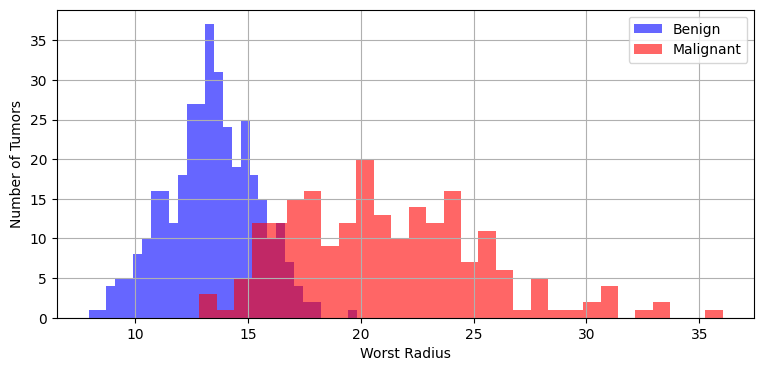

Benign: from 7.93 to 19.82
Malignant: from 12.84 to 36.04


In [11]:
radius = cancer.data["worst radius"]

plt.figure(figsize=(9, 4))
plt.hist(radius[~y], bins=30, alpha=0.6, color="b", label="Benign")
plt.hist(radius[y], bins=30, alpha=0.6, color="r", label="Malignant")

plt.xlabel("Worst Radius")
plt.ylabel("Number of Tumors")
plt.legend()
plt.grid(True)
plt.show()

print("Benign: from", radius[~y].min(), "to", radius[~y].max())
print("Malignant: from", radius[y].min(), "to", radius[y].max())

Observation: The distributions overlap, particularly around values between 13 and 20.

This means there is no perfect cutoff that separates all malignant and benign tumors using `worst radius` alone.

Just like with the Iris dataset, Logistic Regression must learn the best possible decision boundary despite overlapping classes.

### 2.2 Splitting the Data and Training the Model

We use `train_test_split()` to divide the dataset into training and testing sets.

In [12]:
X = cancer.data[["worst radius"]].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

print("w (coef_)      =", log_reg.coef_)
print("b (intercept_) =", log_reg.intercept_)

Train: (426, 1) Test: (143, 1)
w (coef_)      = [[1.05218536]]
b (intercept_) = [-17.66125666]


Key concepts:

- `X`: Contains the input feature (`worst radius`). Double brackets keep it as a 2D DataFrame before converting it into an array.
- `train_test_split()`: Divides the data into training and testing sets.
- `stratify=y`: Preserves approximately the same proportion of malignant and benign samples in both sets (around 37% malignant).
- `random_state=42`: Ensures reproducible data splitting.
- `fit()`: Trains the Logistic Regression model using the training data.
- `coef_`: Contains the learned weight (`w`).
- `intercept_`: Contains the learned bias (`b`).

### 2.3 Predicted Probabilities and Decision Boundary

After training, we generate predictions across a range of `worst radius` values to visualize how the model assigns probabilities to each class.

In [13]:
X_new = np.linspace(5, 40, 1000).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)

decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

Understanding the code:

- `np.linspace(5, 40, 1000)`: Generates 1,000 evenly spaced values between 5 and 40.
- `predict_proba()`: Calculates the predicted probabilities for both classes.
- `y_proba[:, 0]`: Probability of a benign tumor.
- `y_proba[:, 1]`: Probability of a malignant tumor.
- `decision_boundary`: Finds the first feature value where the predicted probability of malignancy reaches or exceeds 0.5.

### Visualizing the Model

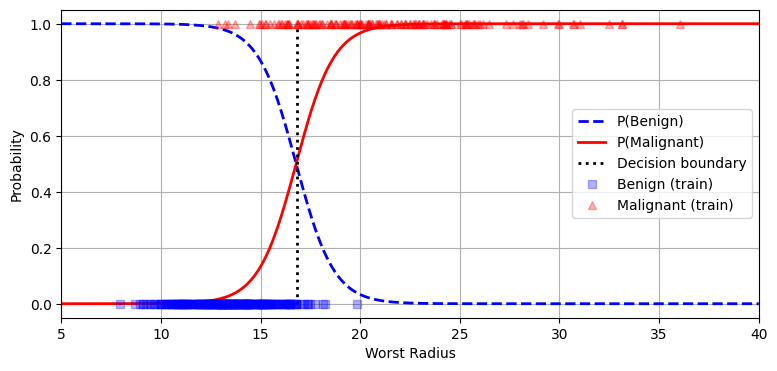

In [14]:
plt.figure(figsize=(9, 4))

plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="P(Benign)")
plt.plot(X_new, y_proba[:, 1], "r-", linewidth=2, label="P(Malignant)")

plt.plot(
    [decision_boundary, decision_boundary], [0, 1],
    "k:", linewidth=2, label="Decision boundary"
)

plt.plot(
    X_train[~y_train], np.zeros((~y_train).sum()),
    "bs", alpha=0.3, label="Benign (train)"
)

plt.plot(
    X_train[y_train], np.ones(y_train.sum()),
    "r^", alpha=0.3, label="Malignant (train)"
)

plt.xlabel("Worst Radius")
plt.ylabel("Probability")
plt.axis([5, 40, -0.05, 1.05])
plt.legend(loc="center right")
plt.grid(True)
plt.show()

The graph shows:

- The blue dashed curve represents the probability of a benign tumor.
- The red solid curve represents the probability of a malignant tumor.
- The vertical dotted line marks the decision boundary.
- The blue squares represent benign training samples.
- The red triangles represent malignant training samples.

The two probability curves cross at approximately 0.5, marking the point where the model changes its predicted class.

### Verifying the Decision Boundary Mathematically

We can calculate the same decision boundary directly from the learned weight and bias:

In [15]:
w_c = log_reg.coef_[0, 0]
b_c = log_reg.intercept_[0]

print("Decision boundary (linspace):", decision_boundary)
print("Decision boundary (-b/w):", -b_c / w_c)

Decision boundary (linspace): 16.806806806806808
Decision boundary (-b/w): 16.785309181554375


The mathematical formula is:

$$w \cdot x+b=0 $$

Therefore:

$$x=-\frac{b}{w} $$

Both methods should produce approximately the same result. Small differences may occur because `linspace` searches through discrete values, while `-b/w` calculates the boundary directly.

Key takeaway: With one feature, Logistic Regression learns a single decision boundary. However, because benign and malignant samples overlap, some tumors will inevitably be misclassified using `worst radius` alone.

In [16]:
print(log_reg.predict_proba([[14], [17], [20]]).round(3))
print(log_reg.predict([[14], [17], [20]]))

[[0.949 0.051]
 [0.444 0.556]
 [0.033 0.967]]
[False  True  True]


---
### 2.4 Evaluating the Model: Confusion Matrix

Accuracy alone is not enough to evaluate a medical classification model. We also need to understand what types of errors the model makes.

There are two important types of classification errors:

- False Positive (FP): The model predicts malignant, but the tumor is actually benign. This can cause unnecessary worry and additional medical tests.
- False Negative (FN): The model predicts benign, but the tumor is actually malignant. This means a cancer case goes undetected. This is generally the more serious error in this context.

Test Accuracy: 0.909


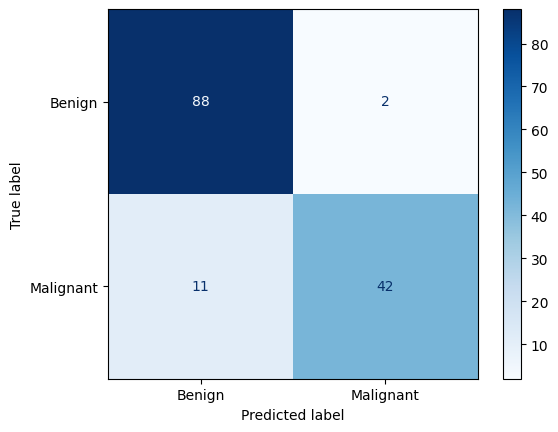

In [17]:
print("Test Accuracy:", round(log_reg.score(X_test, y_test), 3))

ConfusionMatrixDisplay.from_estimator(
    log_reg,
    X_test,
    y_test,
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.show()

Understanding the results:

| Metric              | Meaning                                            |
| ------------------- | -------------------------------------------------- |
| True Positive (TP)  | Correctly identified malignant tumors.             |
| True Negative (TN)  | Correctly identified benign tumors.                |
| False Positive (FP) | Benign tumors incorrectly classified as malignant. |
| False Negative (FN) | Malignant tumors incorrectly classified as benign. |

Key takeaway: In medical screening, reducing false negatives is especially important because missing a malignant tumor can delay diagnosis and treatment.

### 2.5 Adjusting the Decision Threshold

The default decision threshold of `0.5` is not mandatory. We can change it depending on the problem and the cost of different classification errors.

- Lower threshold: The model classifies a tumor as malignant with less predicted probability. This generally detects more malignant cases but also increases false positives.
- Higher threshold: The model requires greater confidence before classifying a tumor as malignant. This generally reduces false positives but increases the risk of false negatives.

In [18]:
p_test = log_reg.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.3, 0.2]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, p_test >= threshold
    ).ravel()

    boundary = X_new[
        log_reg.predict_proba(X_new)[:, 1] >= threshold
    ][0, 0]

    print(
        f"Threshold {threshold}: boundary = {boundary:5.2f} | "
        f"False negatives = {fn:2d}, "
        f"False positives = {fp:2d}"
    )

Threshold 0.5: boundary = 16.81 | False negatives = 11, False positives =  2
Threshold 0.3: boundary = 16.00 | False negatives =  7, False positives =  8
Threshold 0.2: boundary = 15.48 | False negatives =  1, False positives = 13


What happens when we lower the threshold?

The model becomes more sensitive to potential malignant cases:

- More malignant tumors may be correctly detected (higher TP).
- Fewer malignant tumors may be missed (lower FN).
- More benign tumors may be incorrectly flagged (higher FP).

This illustrates the trade-off between detecting positive cases and avoiding false alarms.

### Choosing the Threshold Automatically (Optional)

The model learns its weights (`w`) and bias (`b`) during training, but the decision threshold is a separate choice.

The default threshold of `0.5` is a convention, not a universal rule. In a real-world project, we should:

1. Decide which classification error is more costly.
2. Select an appropriate evaluation metric.
3. Use cross-validation on the training data to find a suitable threshold.
4. Evaluate the final model on the test set without using it to select the threshold.

For this example, we use F2-score, which gives more importance to Recall than Precision.

- Precision: Of all samples predicted as malignant, how many were actually malignant?
- Recall: Of all actual malignant samples, how many did the model correctly identify?
- F2-score: Combines Precision and Recall while giving Recall more weight.

The F2-score is useful when missing a malignant case is considered more costly than generating a false alarm.

In [19]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import make_scorer, fbeta_score

f2 = make_scorer(fbeta_score, beta=2)

adjusted = TunedThresholdClassifierCV(
    LogisticRegression(random_state=42),
    scoring=f2,
    cv=5,
    random_state=42
)

adjusted.fit(X_train, y_train)

tn, fp, fn, tp = confusion_matrix(
    y_test, adjusted.predict(X_test)
).ravel()

print(
    "Threshold selected through cross-validation:",
    round(adjusted.best_threshold_, 3)
)

print(f"Test results: False negatives = {fn}, False positives = {fp}")

Threshold selected through cross-validation: 0.212
Test results: False negatives = 3, False positives = 11


Understanding the implementation:

- `make_scorer(fbeta_score, beta=2)`: Creates an F2-score evaluation metric.
- `TunedThresholdClassifierCV`: Searches for a decision threshold that optimizes the selected metric.
- `cv=5`: Uses five-fold cross-validation to evaluate different thresholds.
- `fit(X_train, y_train)`: Finds the threshold using only the training data.
- `best_threshold_`: Returns the selected decision threshold.
- `predict(X_test)`: Evaluates the model on previously unseen test data using the selected threshold.

Important: Threshold selection should happen using training data and cross-validation, not by repeatedly testing different thresholds on the test set. Otherwise, information from the test set leaks into model selection.

Key takeaway: Accuracy measures overall correctness, but the Confusion Matrix reveals the types of errors. Adjusting the decision threshold allows us to prioritize detecting malignant tumors, even if that means accepting more false positives.